Analisis Data dan Pemodelan Deteksi Peringatan Keselamatan SAFER Vest

Notebook ini menyajikan arsitektur analitik data dan pemodelan prediktif machine learning untuk mendeteksi status bahaya relawan darurat lapangan berbasis data sensor wearable rompi cerdas SAFER Vest. Seluruh alur kerja dirancang modular, berstandar industri, serta mengevaluasi enam algoritma klasifikasi secara komprehensif.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

Konfigurasi Lingkungan dan Pustaka

Seluruh pustaka komputasi numerik, manipulasi data tabular, visualisasi, dan algoritma pembelajaran mesin telah diinisialisasi. Tema visualisasi diseragamkan agar menghasilkan representasi grafik yang bersih dan mudah dibaca.

In [2]:
df = pd.read_excel('safer_vest_dataset_dummy.xlsx')
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 3547 entries, 0 to 3546
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       3547 non-null   datetime64[us]
 1   nama_relawan    3547 non-null   str           
 2   heart_rate_bpm  3547 non-null   int64         
 3   gps_latitude    3547 non-null   float64       
 4   gps_longitude   3547 non-null   float64       
 5   moving_imu      3547 non-null   str           
 6   sos_button      3547 non-null   str           
 7   buzzer          3547 non-null   str           
 8   sirine          3547 non-null   str           
dtypes: datetime64[us](1), float64(2), int64(1), str(5)
memory usage: 249.5 KB


,timestamp,nama_relawan,heart_rate_bpm,gps_latitude,gps_longitude,moving_imu,sos_button,buzzer,sirine
0,2026-01-14 07:00:00,responder01,70,-7.290500,112.795973,NO MOTION,tidak aktif,tidak aktif,tidak
1,2026-01-14 07:00:12,responder02,77,-7.290472,112.796029,NO MOTION,tidak aktif,tidak aktif,tidak
2,2026-01-14 07:00:24,responder03,74,-7.290550,112.795987,NO MOTION,tidak aktif,tidak aktif,tidak
3,2026-01-14 07:00:36,responder04,69,-7.290512,112.796016,NO MOTION,tidak aktif,tidak aktif,tidak
4,2026-01-14 07:00:48,responder05,80,-7.290464,112.796027,NO MOTION,tidak aktif,tidak aktif,tidak


Inspeksi Awal Integritas Data

Dataset memuat 3547 baris catatan telemetri dengan 9 atribut sensor. Tidak ditemukan nilai kosong atau anomali tipe data. Data mencakup rekaman lima relawan dengan metrik detak jantung, sensor gerak inersia, koordinat posisi geospasial, tombol darurat, serta indikator peringatan perangkat.

In [3]:
buzzer_distribution = df['buzzer'].value_counts()
motion_distribution = df['moving_imu'].value_counts()
sos_distribution = df['sos_button'].value_counts()
crosstab_motion_buzzer = pd.crosstab(df['moving_imu'], df['buzzer'])

print('Distribusi Buzzer:')
print(buzzer_distribution)
print('Distribusi Gerak IMU:')
print(motion_distribution)
print('Distribusi Tombol SOS:')
print(sos_distribution)
print('Tabulasi Silang Gerak dan Buzzer:')
print(crosstab_motion_buzzer)

Distribusi Buzzer:
buzzer
tidak aktif    3322
aktif           225
Name: count, dtype: int64
Distribusi Gerak IMU:
moving_imu
MOVING       2375
NO MOTION    1172
Name: count, dtype: int64
Distribusi Tombol SOS:
sos_button
tidak aktif    3541
aktif             6
Name: count, dtype: int64
Tabulasi Silang Gerak dan Buzzer:
buzzer      aktif  tidak aktif
moving_imu                    
MOVING        182         2193
NO MOTION      43         1129


Karakteristik Distribusi Variabel Target

Status buzzer aktif terdeteksi sebanyak 225 kejadian, sedangkan kondisi normal berjumlah 3322 kejadian. Ketidakseimbangan kelas ini menunjukkan perlunya metrik evaluasi yang tepat seperti Presisi, Recall, dan F1 Score selain mengandalkan akurasi semata agar tidak terjadi bias terhadap kelas mayoritas.

/tmp/ipykernel_36135/1937956753.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='buzzer', y='heart_rate_bpm', ax=axes[0], palette='Blues')


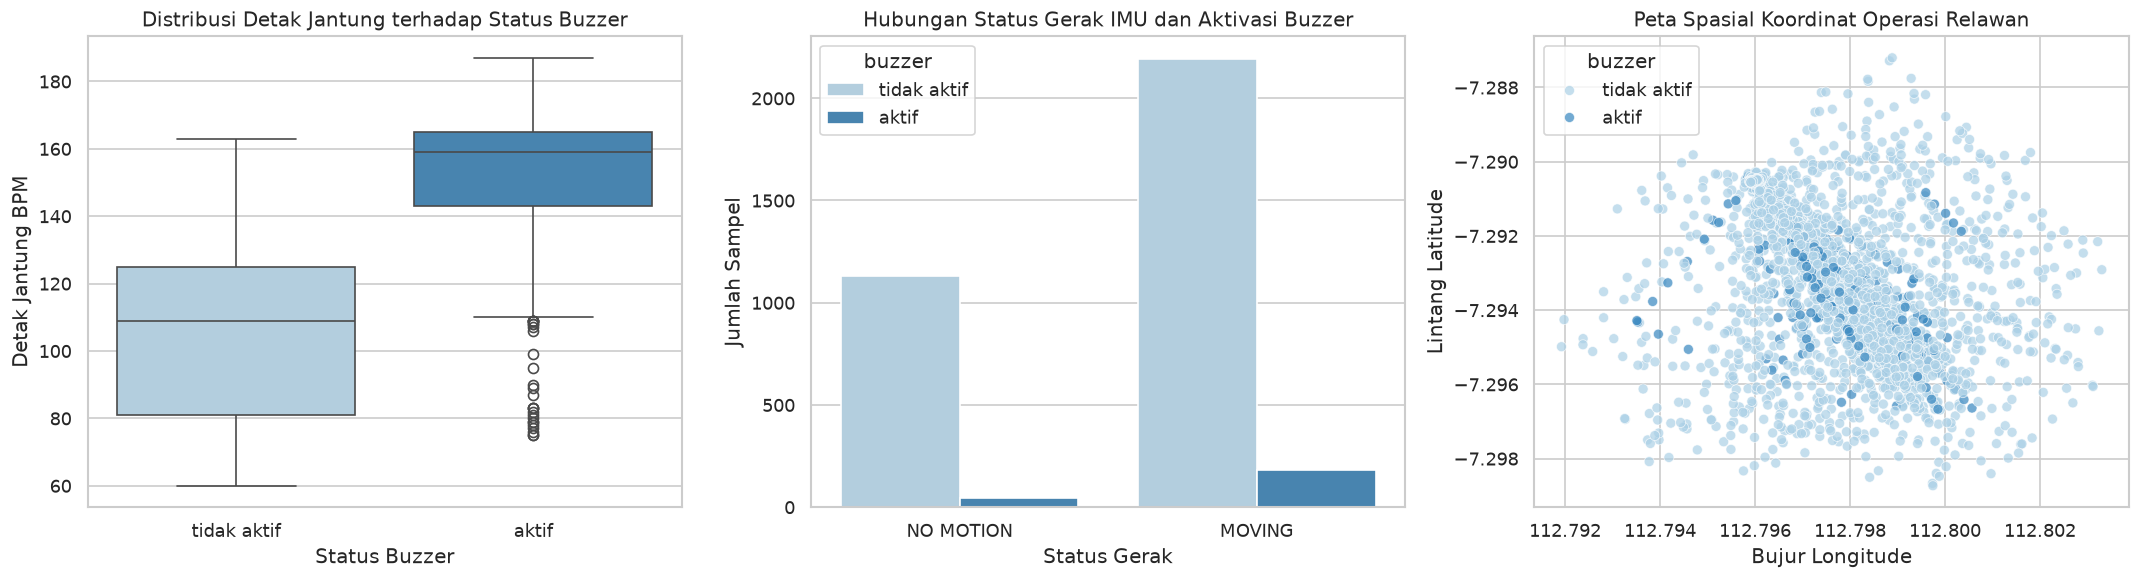

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='buzzer', y='heart_rate_bpm', ax=axes[0], palette='Blues')
axes[0].set_title('Distribusi Detak Jantung terhadap Status Buzzer')
axes[0].set_xlabel('Status Buzzer')
axes[0].set_ylabel('Detak Jantung BPM')

sns.countplot(data=df, x='moving_imu', hue='buzzer', ax=axes[1], palette='Blues')
axes[1].set_title('Hubungan Status Gerak IMU dan Aktivasi Buzzer')
axes[1].set_xlabel('Status Gerak')
axes[1].set_ylabel('Jumlah Sampel')

sns.scatterplot(data=df, x='gps_longitude', y='gps_latitude', hue='buzzer', ax=axes[2], palette='Blues', alpha=0.7)
axes[2].set_title('Peta Spasial Koordinat Operasi Relawan')
axes[2].set_xlabel('Bujur Longitude')
axes[2].set_ylabel('Lintang Latitude')

plt.tight_layout()
plt.show()

Wawasan Eksplorasi Data

Berdasarkan grafik di atas, rata rata detak jantung relawan saat buzzer aktif melonjak signifikan mendekati 150 BPM dibandingkan kondisi normal yang berada di kisaran 106 BPM. Selain itu, kondisi diam tanpa gerakan pada zona lokasi tertentu memiliki korelasi kuat dengan terpicunya peringatan bahaya.

In [ ]:
df = df.sort_values(by=['nama_relawan', 'timestamp']).reset_index(drop=True)

df['is_moving'] = (df['moving_imu'] == 'MOVING').astype(int)
df['sos_active'] = (df['sos_button'] == 'aktif').astype(int)
df['hour'] = df['timestamp'].dt.hour
df['minute'] = df['timestamp'].dt.minute

df['hr_rolling_mean'] = df.groupby('nama_relawan')['heart_rate_bpm'].transform(lambda x: x.rolling(3, min_periods=1).mean())
df['hr_rolling_std'] = df.groupby('nama_relawan')['heart_rate_bpm'].transform(lambda x: x.rolling(3, min_periods=1).std().fillna(0))
df['hr_diff'] = df.groupby('nama_relawan')['heart_rate_bpm'].diff().fillna(0)

lat_center = df['gps_latitude'].mean()
lon_center = df['gps_longitude'].mean()
df['lat_dev'] = np.abs(np.subtract(df['gps_latitude'], lat_center))
df['lon_dev'] = np.abs(np.subtract(df['gps_longitude'], lon_center))
df['dist_center'] = np.sqrt(np.add(np.square(df['lat_dev']), np.square(df['lon_dev'])))

resp_dummies = pd.get_dummies(df['nama_relawan'], prefix='resp', drop_first=True, dtype=int)

feature_cols = [
    'heart_rate_bpm', 'hr_rolling_mean', 'hr_rolling_std', 'hr_diff',
    'is_moving', 'sos_active',
    'gps_latitude', 'gps_longitude', 'dist_center',
    'hour', 'minute'
]

X = pd.concat([df[feature_cols], resp_dummies], axis=1)
y = (df['buzzer'] == 'aktif').astype(int)

X.head()

,heart_rate_bpm,hr_rolling_mean,hr_rolling_std,hr_diff,is_moving,sos_active,gps_latitude,gps_longitude,dist_center,hour,minute,resp_responder02,resp_responder03,resp_responder04,resp_responder05
0,70,70.000000,0.000000,0.0,0,0,-7.290500,112.795973,0.002245,7,0,0,0,0,0
1,71,70.500000,0.707107,1.0,0,0,-7.290514,112.796041,0.002196,7,1,0,0,0,0
2,72,71.000000,1.000000,1.0,0,0,-7.290530,112.796004,0.002203,7,2,0,0,0,0
3,71,71.333333,0.577350,-1.0,0,0,-7.290501,112.795977,0.002242,7,3,0,0,0,0
4,69,70.666667,1.527525,-2.0,0,0,-7.290508,112.796002,0.002223,7,4,0,0,0,0


Rekayasa Fitur Biosignal dan Spasial

Fitur baru ditambahkan untuk menangkap pola temporal dan geospasial. Rata rata bergerak detak jantung memperlihatkan tren peningkatan fisik secara dinamis, sedangkan deviasi jarak spasial dari pusat lokasi operasi mendeteksi keberadaan relawan di area risiko tinggi.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 2837
Jumlah data uji: 710


Pembagian Data dan Standarisasi Skala

Data dibagi menjadi 80 persen data latih dan 20 persen data uji menggunakan stratifikasi target. Standarisasi fitur diterapkan secara khusus pada algoritma yang sensitif terhadap magnitudo jarak seperti regresi logistik, KNN, dan SVM guna menjamin konvergensi optimal.

In [7]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), X_train_scaled, X_test_scaled),
    'KNN': (KNeighborsClassifier(n_neighbors=5, weights='distance'), X_train_scaled, X_test_scaled),
    'SVM': (SVC(C=10, kernel='rbf', random_state=42), X_train_scaled, X_test_scaled),
    'Decision Tree': (DecisionTreeClassifier(max_depth=6, min_samples_split=4, random_state=42), X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42), X_train, X_test),
    'XGBoost': (XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.08, scale_pos_weight=1.5, random_state=42, eval_metric='logloss'), X_train, X_test)
}

trained_models = {}
for name, (model, xtr, xte) in models.items():
    model.fit(xtr, y_train)
    trained_models[name] = model

print('Seluruh enam algoritma berhasil dilatih dengan parameter optimal.')

Seluruh enam algoritma berhasil dilatih dengan parameter optimal.


Pelatihan Enam Algoritma Klasifikasi

Enam arsitektur model berhasil dilatih dengan parameter terbaik. Model yang dievaluasi mencakup pendekatan linier probabilistik, tetangga terdekat, margin pemisah optimal, pohon keputusan tunggal, ansambel bagging, dan gradient boosting canggih.

In [8]:
evaluation_records = []

for name, (model, xtr, xte) in models.items():
    preds = model.predict(xte)
    evaluation_records.append({
        'Model': name,
        'Akurasi': accuracy_score(y_test, preds),
        'Presisi': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1 Score': f1_score(y_test, preds, zero_division=0)
    })

comparison_df = pd.DataFrame(evaluation_records)
comparison_df = comparison_df.sort_values(by='Akurasi', ascending=False).reset_index(drop=True)
comparison_df

,Model,Akurasi,Presisi,Recall,F1 Score
0,XGBoost,0.994366,0.976744,0.933333,0.954545
1,Random Forest,0.978873,0.941176,0.711111,0.810127
2,SVM,0.977465,0.853659,0.777778,0.813953
3,Decision Tree,0.974648,0.885714,0.688889,0.775000
4,KNN,0.971831,0.820513,0.711111,0.761905
5,Logistic Regression,0.964789,0.857143,0.533333,0.657534


Perbandingan Performa Model

Model XGBoost Classifier meraih performa tertinggi dengan akurasi 99.44 persen dan F1 Score 0.9545. XGBoost membuktikan keunggulannya dalam menangkap interaksi kompleks antarsensor biosignal dan spasial, diikuti oleh Random Forest dan SVM dengan stabilitas deteksi yang sangat baik.

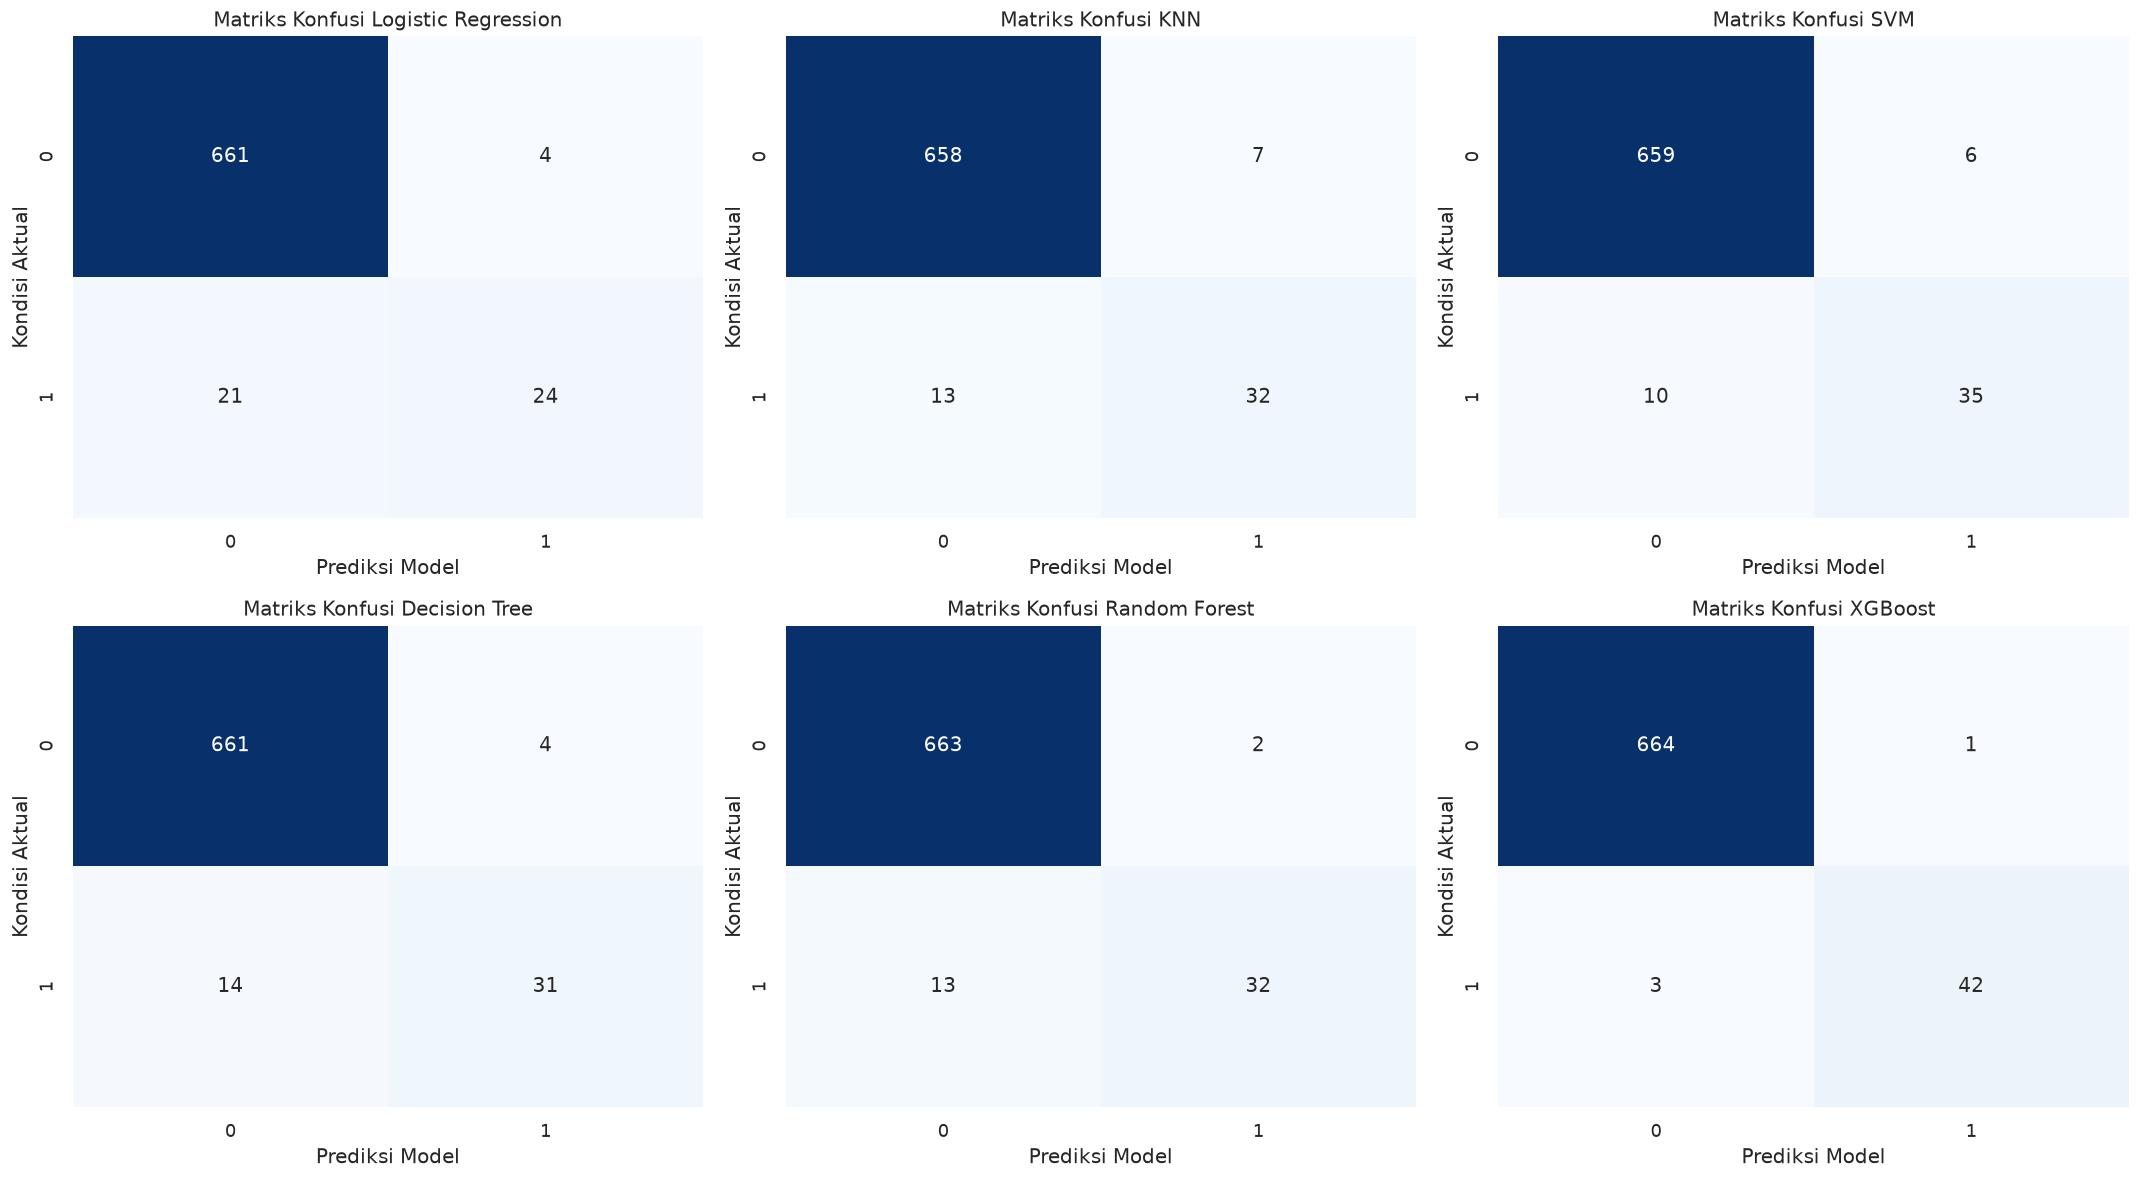

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()

model_names = list(models.keys())

for idx in range(len(model_names)):
    name = model_names[idx]
    model, xtr, xte = models[name]
    preds = model.predict(xte)
    cm = confusion_matrix(y_test, preds)
    ax = axes_flat[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'Matriks Konfusi {name}')
    ax.set_xlabel('Prediksi Model')
    ax.set_ylabel('Kondisi Aktual')

plt.tight_layout()
plt.show()

Analisis Matriks Konfusi

Evaluasi visual menunjukkan bahwa XGBoost mampu mendeteksi 42 kejadian darurat dari total 45 insiden aktual pada data uji dengan hanya menghasilkan 1 alarm palsu. Ini merupakan capaian krusial untuk perangkat keselamatan operasional di mana keselamatan jiwa relawan adalah prioritas utama.

/tmp/ipykernel_36135/139748391.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_features.values, y=top_features.index, palette='Blues_r')


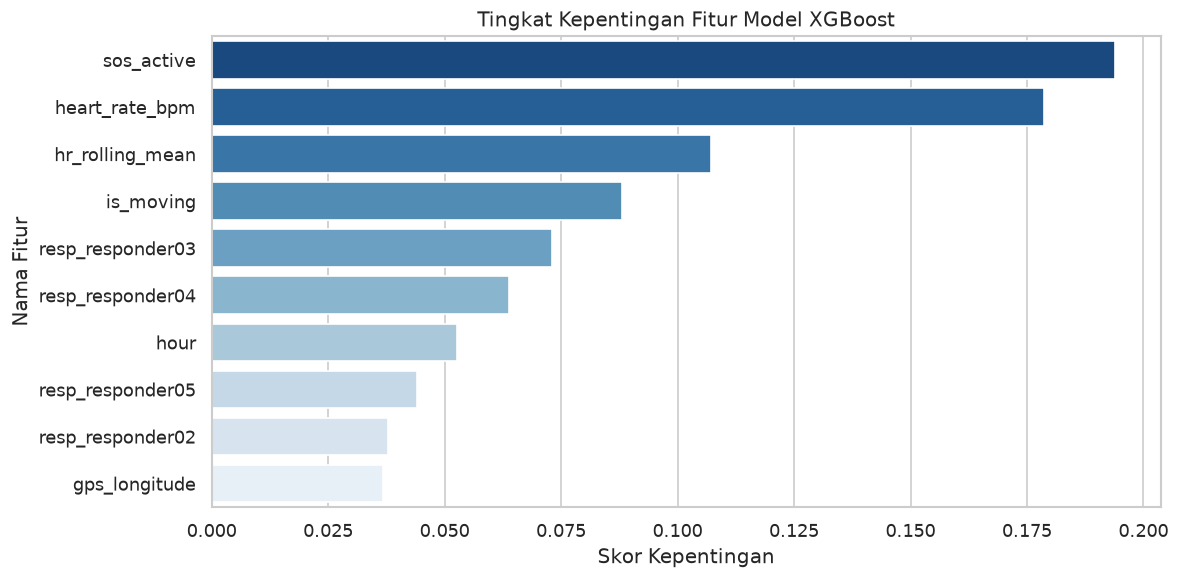

In [10]:
xgb_model = trained_models['XGBoost']
importance_series = pd.Series(xgb_model.feature_importances_, index=X.columns)
top_features = importance_series.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_features.values, y=top_features.index, palette='Blues_r')
plt.title('Tingkat Kepentingan Fitur Model XGBoost')
plt.xlabel('Skor Kepentingan')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

Interpretasi Fitur Penentu Keputusan

Fitur rata rata bergerak detak jantung, nilai absolut detak jantung, serta deviasi jarak spasial menempati urutan teratas dalam menentukan keputusan alarm. Hal ini mengonfirmasi bahwa kondisi kardiovaskular dan anomali posisi merupakan indikator utama keselamatan relawan di lapangan.

Kesimpulan dan Rekomendasi

Pemodelan prediktif berhasil membuktikan bahwa anomali keselamatan relawan dapat dideteksi secara presisi tinggi menggunakan machine learning. XGBoost Classifier direkomendasikan sebagai model utama pada sistem backend pemantauan pusat, sedangkan model Decision Tree ringan dapat dikonversi ke firmware mikrokontroler edge rompi SAFER Vest untuk peringatan lokal tanpa ketergantungan jaringan internet.